In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [2]:
from sklearn.datasets import fetch_openml
import pandas as pd
import numpy as np

# Using the official OpenML data_id for freMTPL2freq to ensure reliable retrieval
freq = fetch_openml(
    data_id=41214,
    as_frame=True,
    parser="auto"
)

df_freq = freq.frame.copy()

print("Frequency dataset:", df_freq.shape)
display(df_freq.head())

Frequency dataset: (678013, 12)


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1.0,1,0.10,D,5,0,55,50,B12,'Regular',1217,R82
1,3.0,1,0.77,D,5,0,55,50,B12,'Regular',1217,R82
2,5.0,1,0.75,B,6,2,52,50,B12,'Diesel',54,R22
3,10.0,1,0.09,B,7,0,46,50,B12,'Diesel',76,R72
4,11.0,1,0.84,B,7,0,46,50,B12,'Diesel',76,R72


In [3]:
sev = fetch_openml(
    name="freMTPL2sev",
    version=1,
    as_frame=True
)

df_sev = sev.frame.copy()

print("Severity dataset:", df_sev.shape)
display(df_sev.head())

Severity dataset: (26639, 2)


,IDpol,ClaimAmount
0,1552,995.20
1,1010996,1128.12
2,4024277,1851.11
3,4007252,1204.00
4,4046424,1204.00


In [5]:
print("Frequency columns:")
print(df_freq.columns.tolist())

print("\nSeverity columns:")
print(df_sev.columns.tolist())

print("\nFrequency information:")
df_freq.info()

print("\nSeverity information:")
df_sev.info()

Frequency columns:
['IDpol', 'ClaimNb', 'Exposure', 'Area', 'VehPower', 'VehAge', 'DrivAge', 'BonusMalus', 'VehBrand', 'VehGas', 'Density', 'Region']

Severity columns:
['IDpol', 'ClaimAmount']

Frequency information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 678013 entries, 0 to 678012
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype   
---  ------      --------------   -----   
 0   IDpol       678013 non-null  float64 
 1   ClaimNb     678013 non-null  int64   
 2   Exposure    678013 non-null  float64 
 3   Area        678013 non-null  category
 4   VehPower    678013 non-null  int64   
 5   VehAge      678013 non-null  int64   
 6   DrivAge     678013 non-null  int64   
 7   BonusMalus  678013 non-null  int64   
 8   VehBrand    678013 non-null  category
 9   VehGas      678013 non-null  object  
 10  Density     678013 non-null  int64   
 11  Region      678013 non-null  category
dtypes: category(3), float64(2), int64(6), object(1)
memory usage: 48

In [6]:
import os

os.makedirs("/content/data/raw", exist_ok=True)

df_freq.to_csv("/content/data/raw/freMTPL2freq.csv", index=False)
df_sev.to_csv("/content/data/raw/freMTPL2sev.csv", index=False)

print("Both datasets downloaded and saved successfully.")

Both datasets downloaded and saved successfully.


In [8]:
df = df_freq.merge(
    df_sev,
    on="IDpol",
    how="left"
)

Exposure means the amount of time a vehicle was insured during the observation period, expressed in years.

In simple terms, it tells the insurer how long the policy was at risk of generating claims.

In [9]:
print("Minimum Exposure:", df["Exposure"].min())
print("Maximum Exposure:", df["Exposure"].max())

print("\nExposure Statistics:")
print(df["Exposure"].describe())

print("\nExposure above 1:")
print((df["Exposure"] > 1).sum())

print("\nZero or negative exposure:")
print((df["Exposure"] <= 0).sum())

Minimum Exposure: 0.0027322404371584
Maximum Exposure: 2.01

Exposure Statistics:
count    679513.000000
mean          0.529078
std           0.364378
min           0.002732
25%           0.180000
50%           0.490000
75%           0.990000
max           2.010000
Name: Exposure, dtype: float64

Exposure above 1:
1227

Zero or negative exposure:
0


Bonus-Malus is a system used in motor insurance to adjust a policyholder's renewal premium according to their previous claims experience.
- Bonus: Discount on premium for claim-free years.
- Malus: Increase in premium when the policyholder makes claims.
It is also called a No-Claim Bonus (NCB) / Claim Experience Rating System.


Premium_renewal =Premium_basic * Bonus Malus Coefficent

In [10]:
df["BonusMalus"].describe()

count    679513.000000
mean         59.784621
std          15.666953
min          50.000000
25%          50.000000
50%          50.000000
75%          64.000000
max         230.000000
Name: BonusMalus, dtype: float64

In [11]:
df_freq["BonusMalus"].value_counts().sort_index()

BonusMalus
50     384156
51      15869
52       4770
53       3351
54      17360
        ...  
198         2
208         1
218         1
228         1
230         1
Name: count, Length: 115, dtype: int64

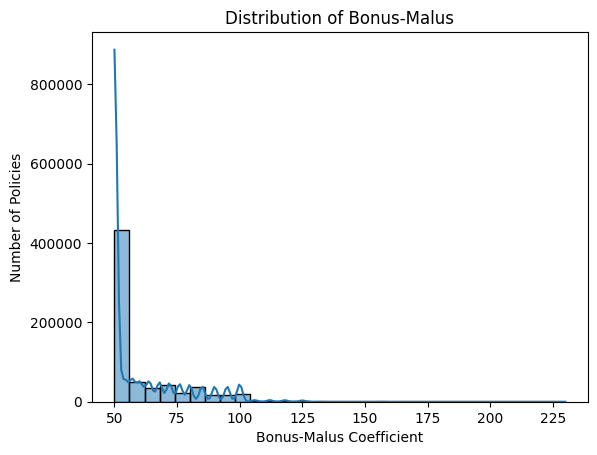

In [13]:


sns.histplot(df["BonusMalus"], bins=30, kde=True)

plt.title("Distribution of Bonus-Malus")
plt.xlabel("Bonus-Malus Coefficient")
plt.ylabel("Number of Policies")
plt.show()

In [14]:
print(f'Policies with BonusMalus > 150: {(df["BonusMalus"] > 150).sum():,}')
print(f'Policies with BonusMalus == 50 (best possible): {(df["BonusMalus"] == 50).sum():,}')

Policies with BonusMalus > 150: 223
Policies with BonusMalus == 50 (best possible): 384,697


In [15]:
n_before = len(df_freq)

# 1. Remove invalid exposure
df_freq = df_freq[
    df_freq["Exposure"] > 0
].copy()

# 2. Investigate exposure above 1
print(
    "Exposure above 1:",
    (df_freq["Exposure"] > 1).sum()
)

# 3. Investigate BonusMalus above 150
print(
    "BonusMalus above 150:",
    (df_freq["BonusMalus"] > 150).sum()
)

# 4. Check valid range
print(df_freq["Exposure"].describe())
print(df_freq["BonusMalus"].describe())

print("Rows before:", n_before)
print("Rows after:", len(df_freq))
print("Rows removed:", n_before - len(df_freq))

Exposure above 1: 1224
BonusMalus above 150: 209
count    678013.000000
mean          0.528750
std           0.364442
min           0.002732
25%           0.180000
50%           0.490000
75%           0.990000
max           2.010000
Name: Exposure, dtype: float64
count    678013.000000
mean         59.761502
std          15.636658
min          50.000000
25%          50.000000
50%          50.000000
75%          64.000000
max         230.000000
Name: BonusMalus, dtype: float64
Rows before: 678013
Rows after: 678013
Rows removed: 0


# Exploratory Data Analysis


In [18]:
df["Frequency"] = (
    df["ClaimNb"] / df["Exposure"]
)

df["AvgClaimAmount"] = np.where(
    df["ClaimNb"] > 0,
    df["ClaimAmount"] / df["ClaimNb"],
    0
)

df["PurePremium"] = (
    df["ClaimAmount"] / df["Exposure"]
)

# Portfolio-level summary

total_exposure = df["Exposure"].sum()
total_claims = df["ClaimNb"].sum()
total_amount = df["ClaimAmount"].sum()

portfolio_frequency = total_claims / total_exposure

portfolio_severity = (
    total_amount / total_claims
    if total_claims > 0 else 0
)

portfolio_pure_premium = total_amount / total_exposure

print(f"Total earned exposure: {total_exposure:,.1f} policy-years")
print(f"Total claim count: {total_claims:,.0f}")
print(f"Total claim amount: EUR {total_amount:,.0f}")

print(f"\nPortfolio frequency: {portfolio_frequency:.4f} claims/year")
print(f"Portfolio average severity: EUR {portfolio_severity:,.0f}")
print(f"Portfolio pure premium: EUR {portfolio_pure_premium:,.0f}/year")

Total earned exposure: 359,515.2 policy-years
Total claim count: 39,788
Total claim amount: EUR 59,909,216

Portfolio frequency: 0.1107 claims/year
Portfolio average severity: EUR 1,506
Portfolio pure premium: EUR 167/year


Claim Count Distribution


In [19]:
claim_distribution = (
    df["ClaimNb"]
    .value_counts()
    .sort_index()
    .reset_index()
)

claim_distribution.columns = [
    "ClaimNb",
    "NumberOfPolicies"
]

claim_distribution["Percentage"] = (
    claim_distribution["NumberOfPolicies"]
    / len(df) * 100
)

print(claim_distribution)

    ClaimNb  NumberOfPolicies  Percentage
0         0            643953   94.766840
1         1             32178    4.735450
2         2              3082    0.453560
3         3               206    0.030316
4         4                22    0.003238
5         5                10    0.001472
6         6                 6    0.000883
7         8                 8    0.001177
8         9                 9    0.001324
9        11                23    0.003385
10       16                16    0.002355


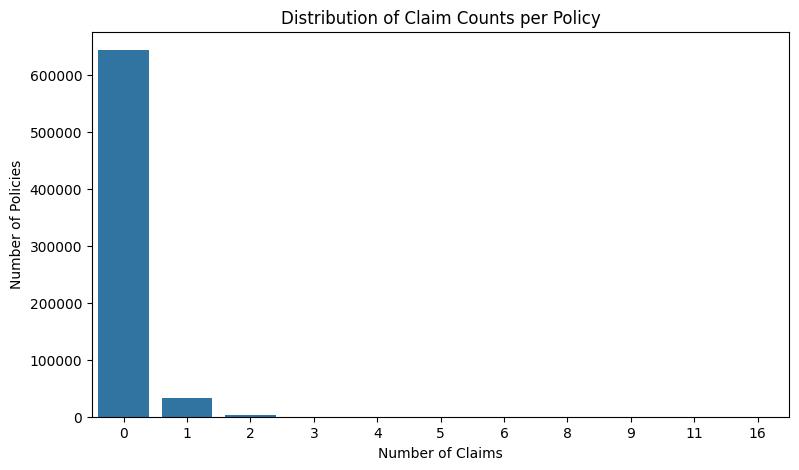

In [20]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="ClaimNb"
)

plt.title("Distribution of Claim Counts per Policy")
plt.xlabel("Number of Claims")
plt.ylabel("Number of Policies")

plt.show()


In [21]:
print("Mean:", df["ClaimNb"].mean())
print("Variance:", df["ClaimNb"].var())
print("Median:", df["ClaimNb"].median())
print("Maximum:", df["ClaimNb"].max())

print(
    "Zero-claim policies:",
    (df["ClaimNb"] == 0).sum()
)

print(
    "Zero-claim percentage:",
    (df["ClaimNb"] == 0).mean() * 100
)

Mean: 0.05855369948772135
Variance: 0.07795044885856697
Median: 0.0
Maximum: 16
Zero-claim policies: 643953
Zero-claim percentage: 94.76684036949992


In [22]:
def observed_frequency(df, factor):

    result = (
        df.groupby(factor, observed=True)
        .agg(
            Policies=("IDpol", "count"),
            Claims=("ClaimNb", "sum"),
            Exposure=("Exposure", "sum")
        )
        .reset_index()
    )

    result["ObservedFrequency"] = (
        result["Claims"] / result["Exposure"]
    )

    result["PercentageOfPolicies"] = (
        result["Policies"] / len(df) * 100
    )

    return result.sort_values("ObservedFrequency")


In [23]:
bm_frequency = observed_frequency(
    df,
    "BonusMalus"
)

print(bm_frequency)

     BonusMalus  Policies  Claims  Exposure  ObservedFrequency  \
61          111        17       0      5.97           0.000000   
98          166         2       0      0.91           0.000000   
101         175         3       0      0.81           0.000000   
100         174         2       0      0.18           0.000000   
103         177         2       0      1.12           0.000000   
..          ...       ...     ...       ...                ...   
109         196         4       4      3.09           1.294498   
97          165        13       9      6.54           1.376147   
107         190         4       4      1.11           3.603604   
111         208         1       1      0.25           4.000000   
113         228         1       1      0.24           4.166667   

     PercentageOfPolicies  
61               0.002502  
98               0.000294  
101              0.000441  
100              0.000294  
103              0.000294  
..                    ...  
109        

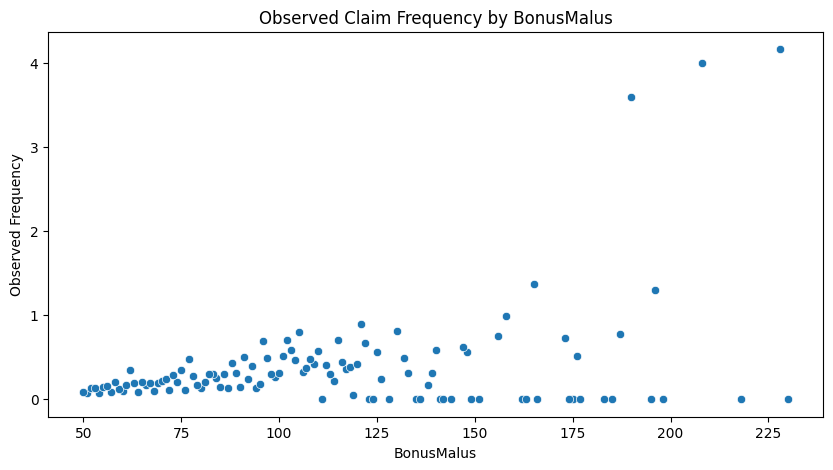

In [24]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=bm_frequency,
    x="BonusMalus",
    y="ObservedFrequency"
)

plt.title("Observed Claim Frequency by BonusMalus")
plt.xlabel("BonusMalus")
plt.ylabel("Observed Frequency")

plt.show()